# 01 · Data profiling

**Goal:** check what the data really contains *before* designing the dashboard. Every claim about coverage in the project should come from this notebook, not from memory.

**Hypotheses to confirm or refute**

1. Serve statistics and match duration are only reliable from the early 1990s.
2. Ranking columns inside the match rows are incomplete in the earliest seasons.
3. The latest season is partial and must be excluded or flagged.
4. Categorical fields (`tourney_level`, `tourney_name`, `surface`) need cleaning rules.

**Data:** [TML-Database](https://github.com/Tennismylife/TML-Database) and [TML-Rankings-Database](https://github.com/Tennismylife/TML-Rankings-Database), downloaded with `src/download_data.py`. Originally inspired by Jeff Sackmann's tennis_atp (CC BY-NC-SA 4.0).

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

ACCENT = "#F5C518"


def read_csv_robust(path, **kwargs):
    """Read a CSV as UTF-8; fall back to cp1252 if the file is not valid UTF-8."""
    try:
        return pd.read_csv(path, encoding="utf-8-sig", **kwargs)
    except UnicodeDecodeError:
        print(f"  (note) {Path(path).name} is not valid UTF-8 -> reading as cp1252")
        return pd.read_csv(path, encoding="cp1252", encoding_errors="replace", **kwargs)


# Locate the repo root whether the notebook runs from the repo root or from notebooks/
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
MATCHES_DIR = RAW / "matches"
PLAYERS_FILE = RAW / "players" / "ATP_Database.csv"
RANKINGS_DIR = RAW / "rankings"

print("Repo root:", ROOT)
print("Raw data folder exists:", RAW.exists())

Repo root: c:\Users\xavi8\Desktop\GitHub\atp-tennis-dashboard
Raw data folder exists: True


## 1. Load matches

In [3]:
frames = []
for path in sorted(MATCHES_DIR.glob("*.csv")):
    df_year = read_csv_robust(path, dtype={"tourney_date": "string"}, low_memory=False)
    df_year["season"] = int(path.stem)
    frames.append(df_year)

matches = pd.concat(frames, ignore_index=True)
matches["date"] = pd.to_datetime(matches["tourney_date"], format="%Y%m%d", errors="coerce")

print(f"{len(matches):,} rows x {matches.shape[1]} columns | seasons {matches.season.min()}-{matches.season.max()}")
print("Unparseable tourney_date:", matches["date"].isna().sum())

# Is the schema the same in every season?
reference = set(frames[-1].columns)
different = {int(f.season.iloc[0]): sorted(set(f.columns) ^ reference) for f in frames if set(f.columns) != reference}
print("Seasons whose columns differ from the latest file:", different if different else "none")

198,063 rows x 52 columns | seasons 1968-2026
Unparseable tourney_date: 0
Seasons whose columns differ from the latest file: none


## 2. Volume per season and completeness of the latest season

A season is treated as *complete* if its last tournament week falls in December.

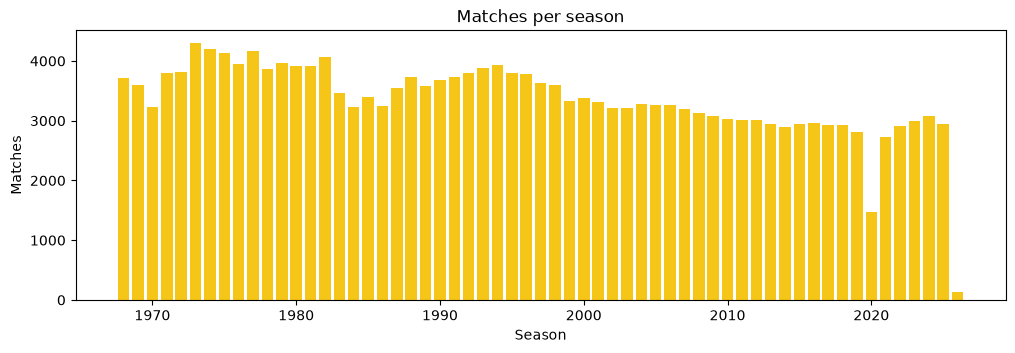

Last complete season: 2025


,matches,last_tourney_date
season,,
2021,2735,2021-12-05
2022,2918,2022-11-27
2023,2995,2023-11-27
2024,3076,2024-12-18
2025,2944,2025-12-22
2026,137,2026-01-17


In [4]:
per_season = matches.groupby("season").agg(matches=("match_num", "size"), last_tourney_date=("date", "max"))
LAST_COMPLETE = int(per_season.index[per_season["last_tourney_date"].dt.month == 12].max())

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(per_season.index, per_season["matches"], color=ACCENT)
ax.set_title("Matches per season")
ax.set_xlabel("Season")
ax.set_ylabel("Matches")
plt.show()

print("Last complete season:", LAST_COMPLETE)
display(per_season.tail(6))

## 3. Coverage: which columns are filled, and since when?

Coverage = share of non-null values per season. Walkovers and defaults carry no statistics by nature, so they are excluded from this calculation to avoid blaming the data for something that is expected.

In [5]:
score = matches["score"].fillna("").astype(str)
is_walkover = score.str.contains("W/O|DEF", regex=True)

STAT_COLS = ["minutes", "w_ace", "w_df", "w_svpt", "w_1stIn", "w_1stWon", "w_2ndWon", "w_SvGms", "w_bpSaved", "w_bpFaced",
             "l_ace", "l_df", "l_svpt", "l_1stIn", "l_1stWon", "l_2ndWon", "l_SvGms", "l_bpSaved", "l_bpFaced"]
RANK_COLS = ["winner_rank", "loser_rank", "winner_rank_points", "loser_rank_points"]
BIO_COLS = ["winner_ht", "loser_ht", "winner_age", "loser_age", "winner_hand", "loser_hand", "winner_ioc", "loser_ioc"]
CONTEXT_COLS = ["surface", "tourney_level", "round", "best_of", "draw_size", "indoor", "score"]

wanted = STAT_COLS + RANK_COLS + BIO_COLS + CONTEXT_COLS
missing_cols = [c for c in wanted if c not in matches.columns]
print("Expected columns not found:", missing_cols if missing_cols else "none")
cols = [c for c in wanted if c in matches.columns]

played = matches.loc[~is_walkover]
coverage = played[cols].notna().groupby(played["season"]).mean().T
print(f"Walkovers/defaults excluded from coverage: {is_walkover.sum():,} of {len(matches):,} rows")

Expected columns not found: none
Walkovers/defaults excluded from coverage: 1,567 of 198,063 rows


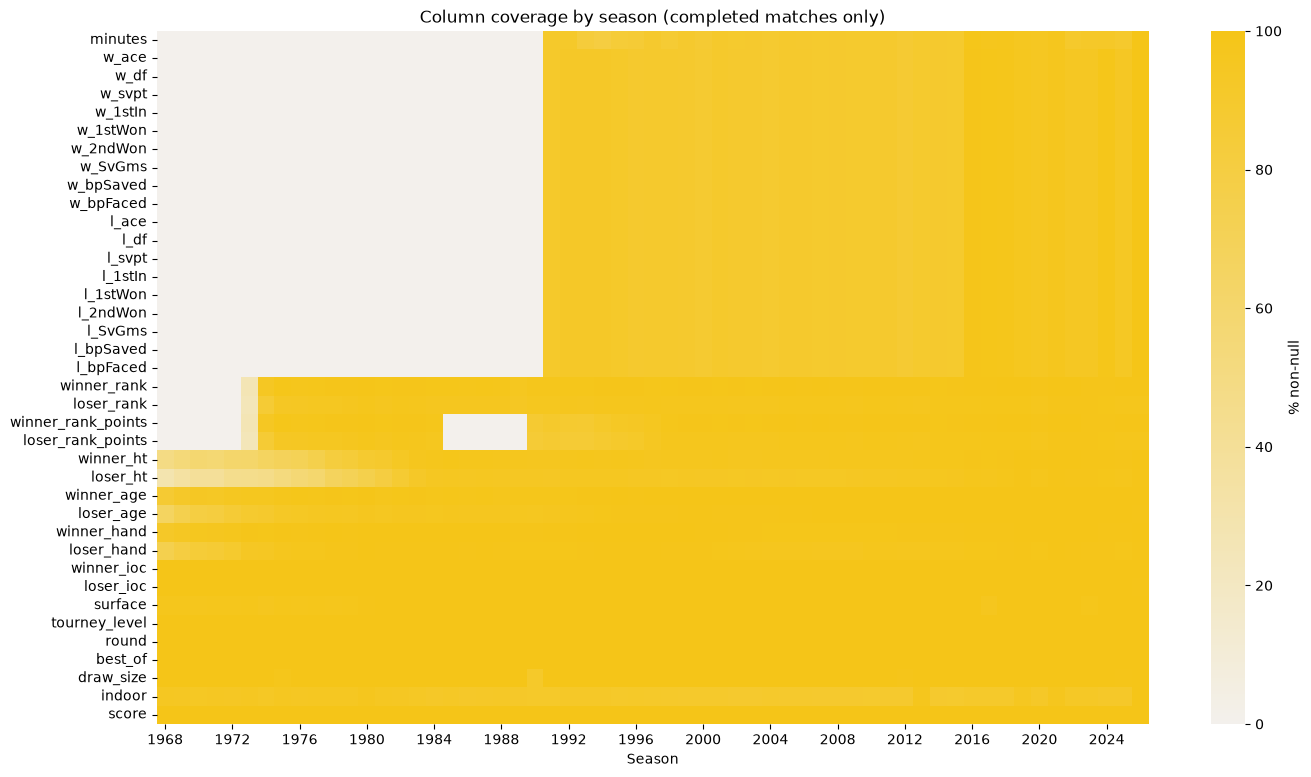

In [6]:
fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(coverage * 100, cmap=sns.light_palette(ACCENT, as_cmap=True), vmin=0, vmax=100,
            xticklabels=4, cbar_kws={"label": "% non-null"}, ax=ax)
ax.set_title("Column coverage by season (completed matches only)")
ax.set_xlabel("Season")
plt.show()

In [7]:
def first_reliable_season(row, threshold=0.8):
    """First season from which coverage stays >= threshold until the last complete season."""
    ok = row.loc[:LAST_COMPLETE] >= threshold
    for season in ok.index:
        if ok.loc[season:].all():
            return season
    return None


threshold_table = pd.DataFrame({
    "first_reliable_season (>=80%)": coverage.apply(first_reliable_season, axis=1),
    f"coverage_{LAST_COMPLETE} (%)": (coverage[LAST_COMPLETE] * 100).round(1),
})
threshold_table

,first_reliable_season (>=80%),coverage_2025 (%)
minutes,1991,90.0
w_ace,1991,94.1
w_df,1991,94.1
w_svpt,1991,94.1
w_1stIn,1991,94.1
w_1stWon,1991,94.1
w_2ndWon,1991,94.1
w_SvGms,1991,94.1
w_bpSaved,1991,94.1
w_bpFaced,1991,94.1


**Reading guide:** `first_reliable_season` is the exact threshold to use in the dashboard notes ("Data available since ..."). A column that never reaches 80% shows `None`.

Overall coverage can hide *where* the gaps are. Serve statistics in recent seasons are not missing at random: check them by tournament level.

In [8]:
recent = played[played["season"].between(2015, LAST_COMPLETE)]
by_level = recent.groupby("tourney_level").agg(
    matches=("w_ace", "size"),
    stats_missing_pct=("w_ace", lambda s: round(s.isna().mean() * 100, 1)),
)
by_level

,matches,stats_missing_pct
tourney_level,,
250,11258,0.3
500,4337,0.1
A,491,15.5
D,2482,41.5
F,181,8.8
G,5437,0.1
M,6143,0.0
O,190,34.7


## 4. Categorical fields

In [9]:
matches["decade"] = (matches["season"] // 10) * 10

for col in ["tourney_level", "surface", "round"]:
    print(f"--- {col} by decade (count) ---")
    display(pd.crosstab(matches[col].fillna("<missing>"), matches["decade"]))

print("--- best_of ---")
display(matches["best_of"].value_counts(dropna=False))

--- tourney_level by decade (count) ---


decade,1960,1970,1980,1990,2000,2010,2020
tourney_level,,,,,,,
250,0,0,0,17551,13829,11152,5837
500,0,0,0,5386,3803,4285,2290
A,6108,32767,28915,401,260,135,460
D,366,2046,2333,3179,3274,2874,1183
F,0,160,138,150,150,166,90
G,845,4431,4665,5080,5080,5080,2921
M,0,0,0,5278,5750,5662,3362
O,0,0,46,127,192,128,128


--- surface by decade (count) ---


decade,1960,1970,1980,1990,2000,2010,2020
surface,,,,,,,
<missing>,144,795,22,0,0,90,53
Carpet,511,7896,5845,5798,1957,58,0
Clay,2908,16069,13881,12969,11106,9198,4735
Grass,2266,6960,4160,3143,3186,3226,1589
Hard,1490,7684,12189,15242,16089,16910,9894


--- round by decade (count) ---


decade,1960,1970,1980,1990,2000,2010,2020
round,,,,,,,
3rd/4th,46,54,2,0,0,2,0
BR,0,0,0,1,3,2,2
F,202,965,834,843,691,667,371
Fs,4,9,0,0,0,0,0
QF,688,3713,3216,3252,2644,2592,1412
R128,633,2135,2528,2880,3072,3200,2216
R16,1061,7172,6332,6496,5248,5184,2808
R256,7,52,0,0,0,0,0
R32,1834,12509,12427,12840,10424,9105,4831


--- best_of ---


best_of
3    154868
5     43006
1       189
Name: count, dtype: int64

In [10]:
# Tournament names: same tournament written in more than one way (case / spaces only)
tmp = matches[["tourney_name"]].dropna().assign(key=lambda d: d["tourney_name"].str.strip().str.lower())
spellings = tmp.drop_duplicates().groupby("key")["tourney_name"].apply(list)
inconsistent = spellings[spellings.apply(len) > 1]
print(f"{len(inconsistent)} tournaments with more than one spelling")
inconsistent.head(15)

3 tournaments with more than one spelling


key
atp cup                                                        [ATP Cup, Atp Cup]
atp tour world championships    [ATP Tour World Championships, ATP Tour World ...
rio de janeiro                                   [Rio de Janeiro, Rio De Janeiro]
Name: tourney_name, dtype: object

In [11]:
# How did the matches end?
outcome = np.select(
    [score.str.contains("W/O", regex=False).to_numpy(),
     score.str.contains("DEF", regex=False).to_numpy(),
     score.str.contains("RET", regex=False).to_numpy()],
    ["walkover", "default", "retirement"],
    default="completed",
)
matches["outcome"] = outcome
print("--- outcome overall ---")
display(matches["outcome"].value_counts())
print("--- outcome by decade (% of matches) ---")
display((pd.crosstab(matches["decade"], matches["outcome"], normalize="index") * 100).round(2))

# The classification above only knows W/O, DEF and RET. What other text suffixes exist in the score?
suffix = score.str.extract(r"([A-Za-z/]+)\s*$")[0].fillna("<none>")
print("--- score suffixes ---")
display(suffix.value_counts().head(15))

--- outcome overall ---


outcome
completed     192449
retirement      4047
walkover        1538
default           29
Name: count, dtype: int64

--- outcome by decade (% of matches) ---


outcome,completed,default,retirement,walkover
decade,,,,
1960,95.05,0.00,0.90,4.04
1970,97.34,0.00,1.18,1.48
1980,98.52,0.00,1.16,0.32
1990,97.64,0.03,1.98,0.35
2000,96.50,0.02,3.10,0.39
2010,96.23,0.01,3.13,0.62
2020,96.63,0.04,2.69,0.65


--- score suffixes ---


0
<none>    192432
RET         4047
W/O         1538
DEF           29
WEA           17
Name: count, dtype: int64

## 5. Duplicates and key integrity

In [12]:
# Missing match numbers must be handled apart: NaN == NaN would look like a duplicate key.
no_num = matches["match_num"].isna()
print("Rows with missing match_num:", int(no_num.sum()))
display(matches[no_num].groupby("season").agg(rows=("tourney_id", "size"), tournaments=("tourney_id", "nunique")))

known = matches[~no_num]
key_dups = known.duplicated(subset=["tourney_id", "match_num"], keep=False)
full_dups = matches.drop(columns=["date", "decade", "outcome"]).duplicated(keep=False)
print("Duplicated (tourney_id, match_num) among rows that have a match_num:", int(key_dups.sum()))
print("Fully identical rows:", int(full_dups.sum()))

same_player = matches["winner_id"] == matches["loser_id"]
print("Winner == loser:", int(same_player.sum()))
if same_player.any():
    display(matches.loc[same_player, ["season", "tourney_id", "tourney_name", "round", "winner_id", "winner_name",
                                      "loser_id", "loser_name", "score"]])

Rows with missing match_num: 489


,rows,tournaments
season,,
2025,489,9


Duplicated (tourney_id, match_num) among rows that have a match_num: 0
Fully identical rows: 0
Winner == loser: 1


,season,tourney_id,tourney_name,round,winner_id,winner_name,loser_id,loser_name,score
62456,1984,1984-407,Rotterdam,F,C044,Ivan Lendl,C044,Jimmy Connors,6-0 1-0 WEA


## 6. Players file and join with matches

In [13]:
players = read_csv_robust(PLAYERS_FILE, low_memory=False)
print("Players:", players.shape)
display(players.head())
display(players.isna().mean().mul(100).round(1).rename("% null").to_frame())

misplaced = players["weight"] > 1000
print("Rows where a birthdate seems to sit in the weight column:", int(misplaced.sum()))
display(players.loc[misplaced, ["id", "player", "birthdate", "weight", "height"]].head())

print("birthdate string lengths:")
display(players["birthdate"].dropna().astype(str).str.len().value_counts())

ids_in_matches = pd.unique(pd.concat([matches["winner_id"], matches["loser_id"]]).dropna())
found = pd.Series(ids_in_matches).isin(players["id"]).mean()
print(f"Distinct player IDs in matches: {len(ids_in_matches):,} | found in players file: {found:.1%}")

  (note) ATP_Database.csv is not valid UTF-8 -> reading as cp1252
Players: (7643, 12)


,id,player,atpname,birthdate,weight,height,turnedpro,birthplace,coaches,hand,backhand,ioc
0,000001,Kodjo Charles Alipoe-Tchotchodji,Kokou Bernard Alipoe-Tchotchodji,19930316.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TGO
1,104421,Martin Vilarrubi,Martin Vilarrubi,19840902.0,NaN,NaN,NaN,NaN,NaN,R,NaN,URU
2,104437,Dekel Valtzer,Dekel Valtzer,19841003.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ISR
3,104631,Harshana Godamanna,Harshana Godamanna,NaN,19851031.0,NaN,NaN,NaN,NaN,NaN,NaN,SRI
4,108586,Augusto Sanabria,Augusto Sanabria,19800604.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ESA


,% null
id,0.0
player,0.0
atpname,0.0
birthdate,37.7
weight,62.8
height,63.3
turnedpro,79.2
birthplace,57.6
coaches,81.5
hand,36.2


Rows where a birthdate seems to sit in the weight column: 8


,id,player,birthdate,weight,height
3,104631,Harshana Godamanna,NaN,19851031.0,NaN
11,108752,Shehab Shehab,NaN,19690804.0,NaN
17,108800,Alexander Lehnhoff,NaN,19770204.0,NaN
19,108803,Jean Max Mangones,NaN,19751029.0,NaN
32,108843,Toufiq Zhalan,NaN,19731206.0,NaN


birthdate string lengths:


birthdate
10    4761
Name: count, dtype: int64

Distinct player IDs in matches: 7,561 | found in players file: 100.0%


## 6b · Players file: shifted rows

In [4]:
players = pd.read_csv(ROOT / "data" / "raw" / "players" / "ATP_Database.csv", encoding="cp1252")

print(players.shape)
print(players.dtypes)
display(players.head())

# the rows whose "weight" looks like a date (more than 1000 cannot be kilograms)
shifted = players[pd.to_numeric(players["weight"], errors="coerce") > 1000]
print(f"\nRows with a date in `weight`: {len(shifted)}")
display(shifted)

(7643, 12)
id                str
player            str
atpname           str
birthdate     float64
weight        float64
height        float64
turnedpro     float64
birthplace        str
coaches           str
hand              str
backhand          str
ioc               str
dtype: object


,id,player,atpname,birthdate,weight,height,turnedpro,birthplace,coaches,hand,backhand,ioc
0,000001,Kodjo Charles Alipoe-Tchotchodji,Kokou Bernard Alipoe-Tchotchodji,19930316.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TGO
1,104421,Martin Vilarrubi,Martin Vilarrubi,19840902.0,NaN,NaN,NaN,NaN,NaN,R,NaN,URU
2,104437,Dekel Valtzer,Dekel Valtzer,19841003.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ISR
3,104631,Harshana Godamanna,Harshana Godamanna,NaN,19851031.0,NaN,NaN,NaN,NaN,NaN,NaN,SRI
4,108586,Augusto Sanabria,Augusto Sanabria,19800604.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ESA



Rows with a date in `weight`: 8


,id,player,atpname,birthdate,weight,height,turnedpro,birthplace,coaches,hand,backhand,ioc
3,104631,Harshana Godamanna,Harshana Godamanna,NaN,19851031.0,NaN,NaN,NaN,NaN,NaN,NaN,SRI
11,108752,Shehab Shehab,Shehab Shehab,NaN,19690804.0,NaN,NaN,NaN,NaN,NaN,NaN,BRN
17,108800,Alexander Lehnhoff,Alexander Lehnhoff,NaN,19770204.0,NaN,NaN,NaN,NaN,NaN,NaN,GUA
19,108803,Jean Max Mangones,Jean Max Mangones,NaN,19751029.0,NaN,NaN,NaN,NaN,NaN,NaN,HAI
32,108843,Toufiq Zhalan,Toufiq Zhalan,NaN,19731206.0,NaN,NaN,NaN,NaN,NaN,NaN,LIB
51,108884,Yuan Xiong Hui,Yuan Xiong Hui,NaN,19810621.0,NaN,NaN,NaN,NaN,NaN,NaN,SIN
66,110795,Sadri Gueche,Sadri Gueche,NaN,19690315.0,NaN,NaN,NaN,NaN,NaN,NaN,ALG
158,110983,Hadiman Hadiman,Hadiman Hadiman,NaN,19501129.0,NaN,NaN,NaN,NaN,NaN,NaN,INA


In [5]:
clean = pd.read_csv(ROOT / "data" / "interim" / "matches_clean.csv",
                    low_memory=False, dtype={"winner_id": str, "loser_id": str})
ids_in_matches = set(clean["winner_id"]) | set(clean["loser_id"])
used = players[players["id"].isin(ids_in_matches)]
print(f"{len(used):,} of {len(players):,} players appear in the cleaned matches")

print("\n% of players with the column filled:")
print((used.notna().mean() * 100).round(1).to_string())

# which name column agrees with the names used in the match rows?
names = pd.concat([
    clean[["winner_id", "winner_name"]].set_axis(["id", "match_name"], axis=1),
    clean[["loser_id", "loser_name"]].set_axis(["id", "match_name"], axis=1),
])
match_name = names.groupby("id")["match_name"].agg(lambda s: s.mode().iloc[0])
used = used.assign(match_name=used["id"].map(match_name))
print(f"\nplayer == match name:  {(used['player'] == used['match_name']).mean():.1%}")
print(f"atpname == match name: {(used['atpname'] == used['match_name']).mean():.1%}")

5,812 of 7,643 players appear in the cleaned matches

% of players with the column filled:
id            100.0
player        100.0
atpname       100.0
birthdate      60.7
weight         43.2
height         43.0
turnedpro      26.2
birthplace     49.3
coaches        21.2
hand           68.4
backhand       19.1
ioc            99.0

player == match name:  99.9%
atpname == match name: 99.9%


## 7. Rankings

The rankings come from a separate repository, in folders. Check what each folder contains before deciding which one feeds the "weeks at No. 1" and "bump chart" views.

In [14]:
folders = sorted(p for p in RANKINGS_DIR.iterdir() if p.is_dir()) if RANKINGS_DIR.exists() else []
print("Folders found:", [f.name for f in folders])

for folder in folders:
    files = sorted(folder.glob("*.csv"))
    print(f"\n=== {folder.name}: {len(files)} files ({files[0].name} ... {files[-1].name}) ===")
    try:
        sample = read_csv_robust(files[0], low_memory=False, nrows=5)
        print("columns:", list(sample.columns))
        display(sample)
    except Exception as exc:
        print("Could not read sample:", exc)

Folders found: ['Official ATP Rankings', 'TML Rankings']

=== Official ATP Rankings: 53 files (1973.csv ... 2025.csv) ===
columns: ['date', 'rank', 'name', 'id', 'points']


,date,rank,name,id,points
0,19730823,1,Ilie Nastase,N008,0
1,19730823,2,Manuel Orantes,O017,0
2,19730823,3,Stan Smith,S060,0
3,19730823,4,Arthur Ashe,A063,0
4,19730823,5,Rod Laver,L058,0



=== TML Rankings: 54 files (1973.csv ... 2026.csv) ===
columns: ['date', 'rank', 'name', 'id', 'points']


,date,rank,name,id,points
0,19730820,1,Ilie Nastase,N008,281
1,19730820,2,Stan Smith,S060,250
2,19730820,3,John Newcombe,N044,136
3,19730820,4,Arthur Ashe,A063,221
4,19730820,5,Tom Okker,O032,187


In [15]:
def load_folder(folder):
    parts = [read_csv_robust(f, low_memory=False).assign(source_file=f.name)
             for f in sorted(folder.glob("*.csv"))]
    return pd.concat(parts, ignore_index=True)


for folder in folders:
    print(f"\n=== {folder.name} ===")
    try:
        df = load_folder(folder)
        date_col = next((c for c in df.columns if "date" in c.lower()), None)
        print("rows:", f"{len(df):,}", "| date column:", date_col)
        if date_col:
            raw_dates = df[date_col].astype("string")
            dates = pd.to_datetime(raw_dates, format="%Y%m%d", errors="coerce")
            if dates.isna().mean() > 0.5:
                dates = pd.to_datetime(raw_dates, errors="coerce")
            snapshots = dates.dropna().drop_duplicates().dt.year.value_counts().sort_index()
            print("ranking snapshots (distinct dates) per year:")
            display(snapshots.to_frame("snapshots").T)
    except Exception as exc:
        print("Could not profile this folder:", exc)


=== Official ATP Rankings ===
rows: 3,347,247 | date column: date
ranking snapshots (distinct dates) per year:


date,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
snapshots,7,10,13,23,33,38,42,43,41,44,43,44,42,41,41,41,43,53,49,49,52,52,52,52,52,51,51,51,53,52,52,52,52,52,53,52,52,52,46,47,46,46,46,46,47,47,47,27,46,46,43,44,23



=== TML Rankings ===
rows: 4,005,491 | date column: date
ranking snapshots (distinct dates) per year:


date,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
snapshots,20,52,52,52,52,52,53,52,52,52,52,53,53,52,52,52,52,53,52,52,52,52,52,53,52,52,52,52,53,52,52,52,52,52,53,52,52,52,52,53,52,52,52,52,52,53,52,30,52,52,52,53,48,3


## 7b · Validating TML Rankings against the official ranking others validations

In [21]:
def load_rank_year(folder, year):
    f = next((ROOT / "data" / "raw" / "rankings").rglob(f"{folder}/{year}.csv"))
    df = read_csv_robust(f, dtype=str)                 # todo como texto primero
    df = df[df["date"] != "date"].copy()               # descarta cabeceras repetidas
    df["date"] = pd.to_datetime(df["date"], format="%Y%m%d")
    df["rank"] = pd.to_numeric(df["rank"], errors="coerce")
    df["points"] = pd.to_numeric(df["points"], errors="coerce")
    return df.sort_values("date")

In [22]:
f = next((ROOT / "data" / "raw" / "rankings").rglob("TML Rankings/2025.csv"))
raw = read_csv_robust(f, dtype=str)

i = 99600                                  # posición de la cabecera repetida
before, after = raw.iloc[:i], raw.iloc[i + 1:]

print("before:", before["date"].min(), "->", before["date"].max(), f"({before['date'].nunique()} dates)")
print("after: ", after["date"].min(),  "->", after["date"].max(),  f"({after['date'].nunique()} dates)")
print("dates in both blocks:", sorted(set(before["date"]) & set(after["date"])))
print("duplicate (date, id) rows:", raw[raw["date"] != "date"].duplicated(["date", "id"]).sum())

before: 20250106 -> 20251215 (46 dates)
after:  20251222 -> 20251229 (2 dates)
dates in both blocks: []
duplicate (date, id) rows: 0


In [26]:
sel = matches["score"].str.contains("W/O|DEF", na=False)
cols = ["tourney_name", "season", "round", "winner_name", "loser_name", "score", "minutes", "w_ace"]
display(matches.loc[sel, cols].sample(8, random_state=1))

,tourney_name,season,round,winner_name,loser_name,score,minutes,w_ace
1559,Roland Garros,1968,R128,Raymond Moore,Marty Riessen,W/O,NaN,NaN
82756,Johannesburg,1989,R16,Dean Botha,Kevin Curren,W/O,NaN,NaN
184119,Barcelona,2021,R32,Bernabe Zapata Miralles,Fabio Fognini,6-0 4-4 DEF,81.0,2.0
52678,Stuttgart-2,1981,R16,Andreas Maurer,Christophe Casa,W/O,NaN,NaN
8116,Kingston,1970,R16,Richard Russell,Luis Ayala,W/O,NaN,NaN
79991,Key Biscayne,1989,R64,Jaime Yzaga,Miloslav Mecir Sr.,W/O,NaN,NaN
179725,Indian Wells Masters,2019,QF,Dominic Thiem,Gael Monfils,W/O,NaN,NaN
178925,Paris Masters,2018,R32,Roger Federer,Milos Raonic,W/O,NaN,NaN


In [27]:
for tag in ["W/O", "DEF", "RET"]:
    s = matches[matches["score"].str.contains(tag, na=False)]
    n_minutes = s["minutes"].notna().sum()
    n_digits = s["score"].str.contains(r"\d", na=False).sum()
    print(f"{tag}: {len(s):>5} rows | with minutes: {n_minutes:>5} | digits in score: {n_digits:>5}")

W/O:  1538 rows | with minutes:    66 | digits in score:     0
DEF:    29 rows | with minutes:    23 | digits in score:    29
RET:  4047 rows | with minutes:  2762 | digits in score:  4047


In [28]:
m = matches[~matches["tourney_level"].isin(["D", "O"])]      # ya sin Copa Davis ni Olímpicos

# 1) ¿Qué torneos son "A" a partir de 1990?
a = m[(m["tourney_level"] == "A") & (m["season"] >= 1990)]
display(a.groupby("tourney_name").size().sort_values(ascending=False).head(15))

# 2) Partidos sin superficie desde el 2000, y dónde aparecen RR / Fs / 3rd/4th / R256
ms = m[m["surface"].isna() & (m["season"] >= 2000)]
display(ms.groupby(["season", "tourney_name"]).size())

rare = m["round"].where(m["round"].isin(["RR", "Fs", "3rd/4th", "R256"]))
display(pd.crosstab(rare, m["tourney_level"]))

tourney_name
World Team Cup             337
World Team Championship    260
ATP Cup                    169
Grand Slam Cup             142
United Cup                 123
Laver Cup                   64
Next Gen Finals             46
NextGen Finals              45
Los Cabos                   27
Doha                        27
Next Gen ATP Finals         15
Atp Cup                      1
dtype: int64

Series([], dtype: int64)

tourney_level,250,A,F,G
round,,,,
3rd/4th,0,98,5,1
Fs,0,13,0,0
R256,0,0,0,59
RR,152,1817,646,0


In [29]:
names = ["Los Cabos", "Doha", "World Team Cup", "World Team Championship",
         "ATP Cup", "Atp Cup", "United Cup", "Laver Cup"]
display(m[m["tourney_name"].isin(names)]
        .groupby(["tourney_name", "tourney_level"])["season"].agg(["count", "min", "max"]))

display(m[(m["round"] == "RR") & (m["tourney_level"] == "250")]
        .groupby(["tourney_name", "season"]).size())

display(m[m["round"] == "Fs"].groupby(["tourney_name", "season"]).size())

count   min   max
tourney_name            tourney_level                   
ATP Cup                 A                169  2020  2022
Atp Cup                 A                  1  2020  2020
Doha                    250              945  1993  2023
                        500               31  2025  2025
                        A                 27  2024  2024
Laver Cup               A                 64  2017  2025
Los Cabos               250              189  2016  2025
                        A                 27  2024  2024
United Cup              A                123  2023  2026
World Team Championship A                260  2003  2012
World Team Cup          A                553  1982  2002

tourney_name  season
Adelaide      2007      32
Buenos Aires  2007      32
Delray Beach  2007      32
Las Vegas     2007      32
Vina del Mar  2007      24
dtype: int64

tourney_name              season
Denver                    1970      2
                          1971      2
Newport WCT               1968      4
Tennis Champions Classic  1971      5
dtype: int64

In [30]:
# 1) 2007: ¿cómo están etiquetadas las rondas de un torneo 250 con "RR"?
display(m[(m["tourney_name"] == "Adelaide") & (m["season"] == 2007)]["round"].value_counts())

# 2) partidos con best_of == 1
display(m[m["best_of"] == 1].groupby(["tourney_name", "season", "tourney_level"]).size())

# 3) las 17 filas WEA
display(m[m["score"].str.contains("WEA", na=False)]
        [["tourney_name", "season", "round", "winner_name", "loser_name", "score", "minutes"]])

# 4) la fila con ganador == perdedor
display(m[m["winner_id"] == m["loser_id"]]
        [["tourney_name", "season", "round", "winner_name", "loser_name", "winner_id", "loser_id", "score"]])

round
RR    32
QF     4
SF     2
F      1
Name: count, dtype: int64

tourney_name        season  tourney_level
Atlanta             1969    A                 1
                    1970    A                 1
Bakersfield WCT     1968    A                 6
Baltimore WCT       1968    A                 4
Berkeley            1969    A                 1
Cannes WCT          1968    A                 1
Chicago             1969    A                11
Corpus Christi      1970    A                 1
Denver              1969    A                15
                    1970    A                25
                    1971    A                24
East London WCT     1968    A                 8
Evansville WCT      1968    A                 7
Hollywood NTL       1968    A                 1
Houston WCT         1968    A                 1
Kimberley WCT       1968    A                 8
Kingston            1973    A                 1
London-2            1969    A                 2
Los Angeles-2       1972    A                 1
Minneapolis WCT     1968    A                 

,tourney_name,season,round,winner_name,loser_name,score,minutes
32456,Nottingham,1976,F,Jimmy Connors,Ilie Nastase,WEA,NaN
34681,WCT Challenge Cup,1976,F,Ilie Nastase,Jimmy Connors,WEA,NaN
36379,Nottingham,1977,F,Jaime Fillol Sr.,Tim Gullikson,WEA,NaN
47069,Rancho Mirage,1980,SF,Jimmy Connors,Brian Teacher,WEA,NaN
47070,Rancho Mirage,1980,SF,Peter Fleming,Gene Mayer,WEA,NaN
51661,Monte-Carlo,1981,F,Guillermo Vilas,Jimmy Connors,5-5 WEA,NaN
62456,Rotterdam,1984,F,Ivan Lendl,Jimmy Connors,6-0 1-0 WEA,NaN
74298,Stratton Mountain,1987,F,John McEnroe,Ivan Lendl,7-6 1-4 WEA,NaN


,tourney_name,season,round,winner_name,loser_name,winner_id,loser_id,score
62456,Rotterdam,1984,F,Ivan Lendl,Jimmy Connors,C044,C044,6-0 1-0 WEA


In [31]:
display(m[m["score"].str.contains("WEA", na=False)]
        [["tourney_name", "season", "round", "winner_name", "loser_name", "score", "minutes"]])

display(m[m["winner_id"] == m["loser_id"]]
        [["tourney_name", "season", "round", "winner_name", "loser_name", "winner_id", "loser_id", "score"]])

,tourney_name,season,round,winner_name,loser_name,score,minutes
32456,Nottingham,1976,F,Jimmy Connors,Ilie Nastase,WEA,NaN
34681,WCT Challenge Cup,1976,F,Ilie Nastase,Jimmy Connors,WEA,NaN
36379,Nottingham,1977,F,Jaime Fillol Sr.,Tim Gullikson,WEA,NaN
47069,Rancho Mirage,1980,SF,Jimmy Connors,Brian Teacher,WEA,NaN
47070,Rancho Mirage,1980,SF,Peter Fleming,Gene Mayer,WEA,NaN
51661,Monte-Carlo,1981,F,Guillermo Vilas,Jimmy Connors,5-5 WEA,NaN
62456,Rotterdam,1984,F,Ivan Lendl,Jimmy Connors,6-0 1-0 WEA,NaN
74298,Stratton Mountain,1987,F,John McEnroe,Ivan Lendl,7-6 1-4 WEA,NaN


,tourney_name,season,round,winner_name,loser_name,winner_id,loser_id,score
62456,Rotterdam,1984,F,Ivan Lendl,Jimmy Connors,C044,C044,6-0 1-0 WEA


In [2]:
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":      # the notebook runs from notebooks/, the project root is one level up
    ROOT = ROOT.parent

In [3]:
clean = pd.read_csv(ROOT / "data" / "interim" / "matches_clean.csv", low_memory=False)

dup = clean[clean.duplicated(["tourney_id", "round", "winner_id", "loser_id"], keep=False)]
display(dup.sort_values(["tourney_id", "round", "winner_id"])
        [["tourney_name", "season", "round", "winner_name", "loser_name", "score", "match_num"]])

,tourney_name,season,round,winner_name,loser_name,score,match_num
6339,Newport,1969,RR,Tom Okker,Roger Taylor,6-3 6-0,2.0
6348,Newport,1969,RR,Tom Okker,Roger Taylor,4-6 6-4 1-0(3),11.0
6340,Newport,1969,RR,Dennis Ralston,Raymond Moore,6-1 6-3,3.0
6345,Newport,1969,RR,Dennis Ralston,Raymond Moore,6-4 6-2,8.0
7300,WCT Aetna World Cup,1970,RR,John Newcombe,Stan Smith,6-3 6-3,1.0
7301,WCT Aetna World Cup,1970,RR,John Newcombe,Stan Smith,7-5 6-3,2.0
9375,Newport-2,1970,RR,Mark Cox,Roger Taylor,6-4 3-6 1-0(1),5.0
9382,Newport-2,1970,RR,Mark Cox,Roger Taylor,6-4 4-6 1-0(3),12.0
9376,Newport-2,1970,RR,Marty Riessen,Roy Emerson,6-5 6-2,6.0
9379,Newport-2,1970,RR,Marty Riessen,Roy Emerson,6-4 4-6 1-0(1),9.0


In [6]:
import sys
sys.path.append(str(ROOT / "src"))
from clean_rankings import load_rankings

INTERIM = ROOT / "data" / "interim"
rankings = load_rankings()

# 1) duplicated (date, id)
dup = rankings[rankings.duplicated(["date", "id"], keep=False)]
print(f"\n{len(dup):,} rows involved; dates: {dup['date'].nunique()}; players: {dup['id'].nunique()}")
display(dup.groupby(["source", "date"]).size().head(15))
display(dup.sort_values(["date", "id"]).head(10))

# 2) missing players by rank cutoff
players = pd.read_csv(INTERIM / "players_clean.csv", usecols=["id"], dtype={"id": str})
missing = ~rankings["id"].isin(players["id"])
print("\nShare of ranking rows whose player is not in the cleaned players:")
for top in (10, 50, 100, 200, 500):
    in_top = rankings["rank"] <= top
    print(f"  top {top:>3}: {(missing & in_top).sum():>7,} of {in_top.sum():>9,} rows "
          f"({(missing & in_top).sum() / in_top.sum():.1%})")

                          rows  snapshots      first       last
source                                                         
Official ATP Rankings     7643         30 1973-08-23 1975-12-15
TML Rankings           3948201       2584 1976-01-05 2025-12-29
Total: 3,955,844 rows

74,253 rows involved; dates: 474; players: 2257


source        date      
TML Rankings  1976-01-05    18
              1976-01-12    18
              1976-01-19    18
              1976-01-26    18
              1976-02-02    18
              1976-02-09    17
              1976-02-16    17
              1976-02-23    15
              1976-03-01    15
              1976-03-08    14
              1976-03-15    11
              1976-03-22    11
              1976-03-29    10
              1976-04-05    10
              1976-04-12    10
dtype: int64

,date,id,rank,points,source
7704,1976-01-05,NaN,62,122.0,TML Rankings
7723,1976-01-05,NaN,81,107.0,TML Rankings
7764,1976-01-05,NaN,121,42.0,TML Rankings
7782,1976-01-05,NaN,140,73.0,TML Rankings
7914,1976-01-05,NaN,268,4.0,TML Rankings
7940,1976-01-05,NaN,281,3.0,TML Rankings
7943,1976-01-05,NaN,281,3.0,TML Rankings
7985,1976-01-05,NaN,322,2.0,TML Rankings
7986,1976-01-05,NaN,322,2.0,TML Rankings
7987,1976-01-05,NaN,322,2.0,TML Rankings



Share of ranking rows whose player is not in the cleaned players:
  top  10:       0 of    26,153 rows (0.0%)
  top  50:     206 of   130,764 rows (0.2%)
  top 100:     763 of   261,593 rows (0.3%)
  top 200:   2,062 of   522,758 rows (0.4%)
  top 500: 150,819 of 1,301,162 rows (11.6%)


In [7]:
RANKINGS_DIR = ROOT / "data" / "raw" / "rankings"

# 1) rows without id
no_id = rankings["id"].isna()
print(f"Rows without id: {no_id.sum():,} ({no_id.mean():.2%} of all rows)")
display(rankings[no_id].groupby(rankings["date"].dt.year // 10 * 10).size().rename("rows_without_id"))
display(rankings[no_id]["rank"].describe())

# 2) duplicates among rows that DO have an id
with_id = rankings[~no_id]
dup_id = with_id[with_id.duplicated(["date", "id"], keep=False)].sort_values(["date", "id"])
print(f"\nDuplicated (date, id) with a real id: {len(dup_id):,} rows, {dup_id['date'].nunique()} dates")
display(dup_id.groupby(dup_id["date"].dt.year // 10 * 10).size().rename("rows"))
display(dup_id.head(10))
print("Identical in rank and points:",
      with_id.duplicated(["date", "id", "rank", "points"], keep=False).sum())

# 3) ids present but not in the cleaned players, top 100 only
players = pd.read_csv(ROOT / "data" / "interim" / "players_clean.csv", usecols=["id"], dtype={"id": str})
unknown = with_id[~with_id["id"].isin(players["id"]) & (with_id["rank"] <= 100)]
print(f"\nTop-100 rows with an id missing from players_clean: {len(unknown):,}, distinct ids: {unknown['id'].nunique()}")
display(unknown.groupby("id").agg(weeks=("date", "size"), best_rank=("rank", "min"),
                                  first=("date", "min"), last=("date", "max")).sort_values("weeks", ascending=False).head(10))

# 4) the raw file itself
raw = pd.read_csv(next(RANKINGS_DIR.rglob("TML Rankings/1976.csv")), dtype=str)
print("\nRaw columns:", list(raw.columns))
display(raw[raw["id"].isna()].head(5))

Rows without id: 69,735 (1.76% of all rows)


date
1970    10993
1980    58742
Name: rows_without_id, dtype: int64

count    69735.000000
mean       644.664702
std        163.794200
min         19.000000
25%        556.000000
50%        671.000000
75%        770.000000
max        856.000000
Name: rank, dtype: float64


Duplicated (date, id) with a real id: 4,518 rows, 4 dates


date
1990       6
2010    4512
Name: rows, dtype: int64

,date,id,rank,points,source
1071724,1995-10-16,W237,983,0.0,TML Rankings
1071725,1995-10-16,W237,983,6.0,TML Rankings
1096342,1996-02-12,W237,994,6.0,TML Rankings
1096343,1996-02-12,W237,994,0.0,TML Rankings
1097793,1996-02-19,W237,989,6.0,TML Rankings
1097794,1996-02-19,W237,989,0.0,TML Rankings
2999562,2016-04-04,A09P,1872,1.0,TML Rankings
3001818,2016-04-04,A09P,1872,1.0,TML Rankings
2999675,2016-04-04,A09T,1990,1.0,TML Rankings
3001931,2016-04-04,A09T,1990,1.0,TML Rankings


Identical in rank and points: 4512

Top-100 rows with an id missing from players_clean: 0, distinct ids: 0


,weeks,best_rank,first,last
id,,,,



Raw columns: ['date', 'rank', 'name', 'id', 'points']


,date,rank,name,id,points
61,19760105,62,Thomaz Koch,NaN,122
80,19760105,81,Jairo Velasco Sr,NaN,107
121,19760105,121,Teimuraz Kakoulia,NaN,42
139,19760105,140,Fred McNair IV,NaN,73
271,19760105,268,Jan-Erik Lundqvist,NaN,4


In [8]:
frames = []
for year in range(1976, 1990):
    f = pd.read_csv(next(RANKINGS_DIR.rglob(f"TML Rankings/{year}.csv")), dtype=str)
    f = f[f["date"] != "date"]
    f["rank"] = pd.to_numeric(f["rank"])
    frames.append(f[f["id"].isna() & (f["rank"] <= 500)])
no_id_top = pd.concat(frames)
print(f"Rows without id inside the top 500: {len(no_id_top):,}; distinct names: {no_id_top['name'].nunique()}")

pl = pd.read_csv(ROOT / "data" / "interim" / "players_clean.csv", usecols=["id", "name"], dtype=str)
print("Names shared by more than one player in players_clean:", pl["name"].duplicated().sum())

names = no_id_top.drop_duplicates("name")[["name"]].merge(pl, on="name", how="left")
matched = names["id"].notna()
print(f"Names matched exactly: {matched.sum()} of {len(names)}")

rows_unmatched = no_id_top[no_id_top["name"].isin(names.loc[~matched, "name"])]
print(f"Rows left without id: {len(rows_unmatched):,} of {len(no_id_top):,}")
display(rows_unmatched.groupby("name").agg(weeks=("date", "size"), best_rank=("rank", "min"))
        .sort_values("best_rank").head(15))

Rows without id inside the top 500: 12,257; distinct names: 237
Names shared by more than one player in players_clean: 31
Names matched exactly: 13 of 237
Rows left without id: 10,512 of 12,257


,weeks,best_rank
name,,
Chris Lewis (NZL),470,19
Teimuraz Kakoulia,110,104
Matt Wooldridge,242,220
Bob Hansen,81,221
Mike Sassano,98,227
Rob Keighery,134,248
Geoff MacDonald,97,252
Greg Neuhart,79,257
Jack Bushman,146,259


In [9]:
pl = pd.read_csv(ROOT / "data" / "interim" / "players_clean.csv",
                 usecols=["id", "name", "ioc", "birthdate"], dtype=str)

# 1) the 13 exact matches: is any name shared by several players?
ok = names[matched].copy()
shared = pl.loc[pl["name"].duplicated(keep=False), "name"]
ok["name_is_shared"] = ok["name"].isin(shared)
display(ok)

# 2) candidates for the two important unmatched names
display(pl[pl["name"].str.contains("Lewis|Kaku", case=False)])

,name,id,name_is_shared
0,Thomaz Koch,K036,False
1,Jairo Velasco Sr,V294,False
3,Fred McNair IV,M146,False
4,Jan-Erik Lundqvist,L158,False
6,Kiyoski Tanabe,T062,False
14,Natsuta Uehara,U159,False
17,Kanyab Derafshijavan,D649,False
21,Bo Svensson,SE09,False
33,Moharram-Ali Khodai,K747,False
85,Glenn Golden,GF51,False


,id,name,ioc,birthdate
2640,K105,Teimuraz Kakulia,RUS,1947-04-26
2841,L024,Chris Lewis,NZL,1957-03-09
2842,L025,Richard Lewis,GBR,1954-12-06
2843,L026,David Lewis,NZL,1964-09-03
2844,L027,Mark Lewis,NZL,NaN
2866,L063,John Chris Lewis,USA,NaN
2920,L0FP,P.R. Lewis,GBR,NaN
2931,L0IS,S. Lewis,GBR,NaN
4846,S439,Sergej Skakun,RUS,NaN
5056,SR44,Lewis Sylvester,RSA,1941-11-04


In [10]:
pl = pd.read_csv(ROOT / "data" / "interim" / "players_clean.csv", dtype=str)
print("Players without country:", pl["ioc"].isna().sum(), "| distinct codes:", pl["ioc"].nunique())
print(pl["ioc"].value_counts().head(15))

Players without country: 60 | distinct codes: 107
ioc
USA    1226
AUS     508
GBR     317
ITA     273
GER     260
RSA     247
FRA     246
ESP     234
ARG     171
SWE     149
JPN     131
CAN     114
NED     108
MEX     102
CZE      97
Name: count, dtype: int64


## 8. Findings and decisions

- **Season range for the dashboard** (complete seasons only): 1968–2025. The 2026 file is stale (137 matches, up to 17 January 2026), so it is excluded.
- **First reliable season for serve statistics and match duration:** 1991 (2025 coverage: about 94% for serve stats and 90% for minutes). Before that, show a "Data available since 1991" note.
- **First reliable season for ranking columns in match rows:** `winner_rank` / `loser_rank` from 1974. Rank points: present for 1974–1984, completely missing for 1985–1989, and continuously available from 1990, so use points only from 1990. Heights: reliable for both players from 1981 (winner height passes 80% in 1978, loser height in 1981, because losers are less documented). The players file is no use for height (63% missing), so use the match-row columns.
- **Which rankings folder to use, and for which years:**
  - 1973–1975: `Official ATP Rankings` (sparse snapshots: 7, 10 and 13 per year; rank points are 0 in the 1973 sample, so unusable). TML Rankings disagrees with the official No. 1 in 6 snapshots: 2 in 1973 (TML shows Newcombe instead of Nastase, an error) and 4 in 1975 (TML shows Vilas, who is not an official No. 1; this matches an unofficial 2015 recalculation).
  - 1976–2025: `TML Rankings` (weekly, 52 snapshots per year; same No. 1 as the official ranking in 100% of the 2,293 weeks compared from 1976 onwards).
  - 2026: only 3 snapshots, stale like the matches. Excluded.
  - Known issue: `TML Rankings/2025.csv` has a repeated header row (row 99,600) because the last two weeks of December were appended. Drop rows where `date == "date"` and convert types explicitly.
- **Cleaning rules needed** (`tourney_level` mapping, tournament-name normalisation, walkovers/defaults, duplicates):
  - **Scope:** drop `tourney_level` D (Davis Cup) and O (Olympics), about 8% of matches; drop the 2026 file. Also drop team competitions, by tournament name and in all years: World Team Cup (1982–2002), World Team Championship (2003–2012), ATP Cup (including the "Atp Cup" spelling), United Cup and Laver Cup (about 1,170 rows, some from 2026). All of them are coded `A`, so they cannot be filtered by level.
  - **Match key and duplicates:** do not use `match_num` as a key (null in 489 rows of 2025, in 9 tournaments, and different for duplicated rows). Four matches of 2021–2025 (Stuttgart, Rome, Gijón, Dubai) are entered twice with a different `match_num`; a duplicate is defined as the same tournament, round, winner, loser and score, and the first row is kept. Repeated pairs with different scores (round-robin formats of 1969–1970) are real matches and are kept.
  - **Tournament names:** normalise with an explicit mapping, not with `.lower()`: "Atp Cup" → "ATP Cup"; "NextGen Finals" and "Next Gen ATP Finals" → "Next Gen Finals"; plus the 3 casing variants found in the profiling.
  - **Players file:** read as cp1252 with the ids as text; the 8 birthdates shifted into `weight` are moved back to `birthdate`. Only the players seen in the cleaned matches are kept (5,812). Name, nationality and hand come from the match rows; the file adds birthdate (61% of players), birthplace (49%), `turnedpro` (26%) and `backhand` (19%). Hand is filled for 68% of players (4 are `A`), the same as in the players file, so charts by hand must report how many players they use. Weight, height, coaches and `atpname` are dropped.
  - **Rankings (`clean_rankings.py`).** Weekly snapshots from two sources: the official ATP ranking for 1973–1975 and TML Rankings for 1976–2025 (2026 excluded, as in matches). The repeated header row in `2025.csv` is dropped when reading. Only the top 500 of each week is kept, and only players present in the cleaned players table. Below rank 500 there are 2.65 million rows, and the remaining top-500 rows from players absent from the players table (about 148,000, all between ranks 101 and 500) belong to players who never appear in an ATP-level match in this dataset, so they cannot be linked to anything. The TML files from 1976 to 1989 have no player id on 69,735 rows; inside the top 500 these are recovered by matching the name against the players table when the name is unique (two spellings fixed by hand: Chris Lewis (NZL) and Teimuraz Kakoulia). About 9,900 top-500 rows remain without id (best rank 220 or lower) and are dropped. Exact duplicate rows (410) are removed; a player appearing twice in a week with different points would keep the higher value (none inside the top 500). Checks: no player twice in a snapshot, and exactly one No. 1 in each of the 2,614 snapshots. The output has no names; they come from the players table through the id.
  - **Match outcome:** add a column `outcome` derived from `score`: `walkover` if it contains "W/O" (1,538 rows, never any digit in the score, so never played); `retired` if it contains "RET" or "DEF" (4,047 + 29 rows, all with a partial score, so they were started; defaults behave like retirements); otherwise `completed`. The 8 `WEA` rows (weather, all semifinals or finals from 1976 to 1987) follow the same logic: no digits in the score means `walkover`, digits means `retired`. Rows are kept. Walkovers count for titles and rounds reached, but not for wins/losses, head-to-head, upsets or serve statistics; their `minutes` are ignored (66 walkovers carry minutes, which cannot be right). Retirements count as results but are excluded from serve statistics and duration.
  - **Tournament level:** add `level_group`: G → Grand Slam; F → Tour Finals; M → Masters (ATP 1000, from 1990); 500 → ATP 500 (from 1990); 250 → ATP 250 (from 1990); `A` before 1990 → Tour event (pre-tiers), because all regular events are `A` until then; `A` from 1990 → Special event (Grand Slam Cup, Next Gen Finals). Fix a coding glitch first: Doha 2024 and Los Cabos 2024 (27 rows each) are coded `A` but are 250 events in every other year, so recode them to 250. Charts that split 250/500/Masters only show 1990 onwards; charts that need the whole series use Grand Slam versus the rest.
  - **Rounds:** `R256` (Grand Slams of the 1960s–70s) is a real round, earlier than R128. `3rd/4th` (104 rows) and `Fs` (13 rows, 1968–1971) are not part of the knockout bracket and do not count as a round reached. `RR` is a real group stage in the Tour Finals (`F`); in 5 tournaments of 2007 (Adelaide, Buenos Aires, Delray Beach, Las Vegas, Viña del Mar; 152 rows) it replaces the rounds before the quarterfinals, so those rows are treated as an unknown early round and left out of rounds-reached analyses. `BR` disappears with the Olympics.
  - **Surface:** all the missing values (1968–1989 and 2010 onwards) belonged to Davis Cup or Olympic matches, so no missing surface remains after the scope filter. The cleaning step keeps a safeguard that labels any future gap as `Unknown`.
  - **`best_of = 1`:** 189 rows, mostly 1968–1973 in professional circuits (WCT, NTL). Keep the rows and exclude them only from analyses that depend on the match format (best of 3 versus best of 5).
  - **Winner equal to loser:** the Rotterdam 1984 final (Lendl–Connors) has the same id (`C044`, Connors') in both columns. Correct the winner id by looking up Lendl's id in his other matches, not by typing it; verify it when building the pipeline.
- **Notes to show in the dashboard** ("Data available since ..."):
  - Serve statistics and match duration: since 1991.
  - Ranking at the time of each match: since 1974; ranking points: since 1990.
  - Tournament categories (250, 500, Masters): since 1990. Before that, all circuit events appear as one group.
  - Scope: singles matches of the ATP circuit up to the 2025 season. Davis Cup, Olympics and team competitions are not included.
  - Weekly rankings for 1973–1975 come from the official ranking, with few snapshots per year.